# Standardized Hidden Units

**Question:** Centering keeps unused units firing only when they fire 50% of the time (07, 08). Does standardizing the hidden units keep them firing when teacher LTUs fire 20% of the time?

Same setup as 08: every teacher LTU fires when $w \cdot x > 4$, on 19.2% of inputs. Standardization divides each unit's centered output by its running standard deviation, $\sqrt{m(1 - m)}$, with the variance floored at 0.01. Like the existing correction for the mean, the backward pass accounts for how that standard deviation changes with the unit's input weights. Each unit's mean square is then fixed at 1, so on average the gradient cannot lower it for units firing on about 1% to 99% of inputs. Below the floor, the push comes back.

SGD and Autostep each run once centered and once standardized. With standardization, SGD scales each readout weight's step size by its unit's variance, so its readout learns as fast as with centering. A unit counts as off when it fires on fewer than 2% of 2000 random inputs.

In [1]:
from functools import partial
from time import perf_counter
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem: 05's schedule, through AFTER_STEPS steps past the 1-task phase
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS, N_HIDDEN = 4, 2 * WIDTH
THRESHOLD = 4  # teacher LTUs fire when w·x > THRESHOLD: 19.2% of inputs
ACTIVE = (4, 3, 2, 1, 2)
GAP = ACTIVE.index(1)  # the 1-task phase
PHASE_STEPS, AFTER_STEPS = 500_000, 60_000

# Learners
SGD_RATE = 2.**-6
INIT_RATE, META_RATE, EMA_RATE = np.exp(-8.), 0.02, 1e-3
OFF = .02  # a unit is off if it fires on fewer than OFF of the probe inputs
VAR_FLOOR = .01  # floor on a standardized unit's variance: protects units firing on about 1% to 99% of inputs
PROBE = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (2000, N_INPUTS)), dtype=jnp.float32)

PERIOD, WINDOW, N_SEEDS = 10_000, 1000, 5

## Task

In [3]:
def init_teacher(key):
    input_key, _, output_key = jax.random.split(key, 3)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > THRESHOLD).astype(jnp.float32)

## Learners

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    weights: tuple
    opt: object
    mean: jax.Array
    slope: jax.Array
    cov: jax.Array


def init_learner(key, method):
    bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / N_INPUTS)
    w = jax.random.uniform(key, (N_HIDDEN, N_INPUTS + 1), minval=-bound, maxval=bound).at[:, -1].set(0.)
    weights = (w, jnp.zeros((N_OUTPUTS, N_HIDDEN + 1)))
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   jnp.full(N_HIDDEN, .5), jnp.zeros_like(w).at[:, -1].set(.25), jnp.zeros_like(w))


def forward(weights, x, learner, norm):
    # norm='center' sends h - m; norm='standardize' sends (h - m) / sd. Both backward passes account for how
    # the running statistics change with the unit's input weights.
    source = jnp.append(x, 1.)
    z = weights[0] @ source
    h, mean, slope, cov = ltu(z), learner.mean, learner.slope, learner.cov
    mean = mean + EMA_RATE * (jax.lax.stop_gradient(h) - mean)
    sigmoid = jax.nn.sigmoid(z)
    derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))[:, None] * source
    slope = slope + EMA_RATE * (derivative - slope)
    correction = jnp.sum(slope * weights[0], axis=1)
    centered = jax.lax.stop_gradient(h - mean)
    h = h - mean + (jax.lax.stop_gradient(correction) - correction)
    if norm == 'standardize':
        # cov tracks Cov(h, sigma'(z) x), half the derivative of the unit's variance with respect to its input weights.
        cov = cov + EMA_RATE * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * weights[0], axis=1)
        h = h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / jnp.maximum(var, VAR_FLOOR), 0.)
        h = h / jax.lax.stop_gradient(jnp.sqrt(jnp.maximum(var, VAR_FLOOR)))
    hidden = jnp.append(h, 1.)
    return weights[1] @ hidden, ((source[None], hidden[None]), mean, slope, cov)


def update(learner, x, y, method, norm):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, norm)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, mean, slope, cov)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        # Standardized outputs are 1/sd times larger than centered ones. Scaling each readout weight's step size by
        # its unit's variance keeps SGD's readout as fast as with centering.
        scale = jnp.append(jnp.maximum(mean * (1 - mean), VAR_FLOOR), 1.) if norm == 'standardize' else 1.
        updates, opt = (-SGD_RATE * grads[0], -SGD_RATE * scale * grads[1]), None
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, mean, slope, cov), 2 * loss_value / N_OUTPUTS

## Training

In [5]:
def train(seed, method, norm):
    teacher_key, learner_key, schedule_key, rng = jax.random.split(jax.random.PRNGKey(seed), 4)
    teachers = jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))
    active = jnp.repeat(jnp.array(ACTIVE), PHASE_STEPS // PERIOD)
    probe = jnp.append(PROBE, jnp.ones((len(PROBE), 1)), axis=1)

    def block(carry, block_id):
        learner, rng, task_id = carry
        task_id = jnp.where(block_id == 0, task_id, (task_id + 1) % active[block_id])
        teacher = jax.tree.map(lambda w: w[task_id], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            learner, mse = update(learner, x, y, method, norm)
            return (learner, rng), mse

        def record(carry, _):
            # Window mean of the MSE; fraction of hidden units that are off at the window's end.
            carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
            firing = jnp.mean(probe @ carry[0].weights[0].T > 0, axis=0)
            return carry, (mse.mean(), jnp.mean(firing < OFF))

        (learner, rng), records = jax.lax.scan(record, (learner, rng), length=PERIOD // WINDOW)
        return (learner, rng, task_id), records

    carry = (init_learner(learner_key, method), rng, jax.random.randint(schedule_key, (), 0, N_TASKS))
    _, (mse, off) = jax.lax.scan(block, carry, jnp.arange(((GAP + 1) * PHASE_STEPS + AFTER_STEPS) // PERIOD))
    gap_start, gap_end = GAP * PHASE_STEPS // WINDOW, (GAP + 1) * PHASE_STEPS // WINDOW
    return off.reshape(-1)[gap_start:gap_end], mse.reshape(-1)[gap_end:]  # off-fraction through the 1-task phase, MSE after it


@partial(jax.jit, static_argnames=('method', 'norm'))
def train_many(method, norm):
    return jax.vmap(partial(train, method=method, norm=norm))(jnp.arange(N_SEEDS))


def run(method, norm):
    return jax.tree.map(np.asarray, train_many(method, norm))

In [6]:
started = perf_counter()
runs = {'SGD + centering': run('SGD', 'center'),
        'SGD + standardization': run('SGD', 'standardize'),
        'Autostep': run('Autostep', 'center'),
        'Autostep + standardization': run('Autostep', 'standardize')}
print(f'{perf_counter() - started:.1f}s including compilation')

119.7s including compilation


## Plots

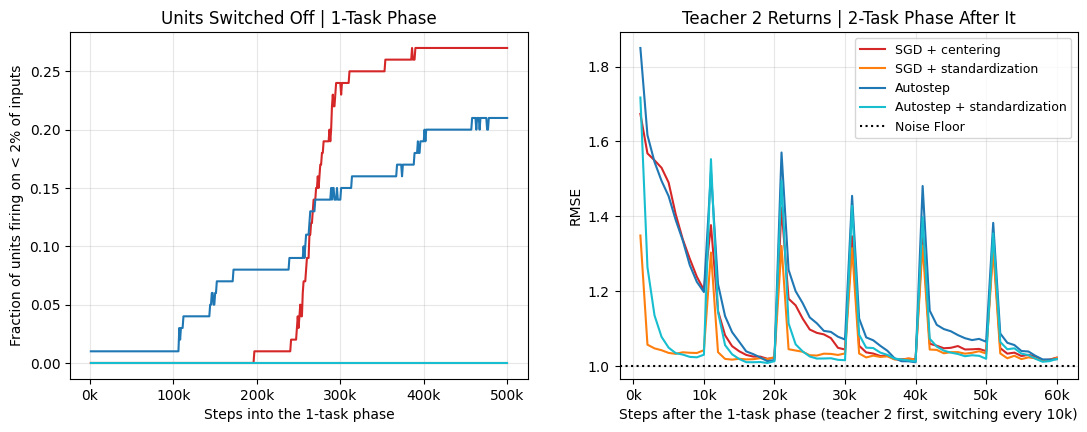

SGD + centering: 27% of units off at the end of the 1-task phase; RMSE over steps 2k-10k of the first block back 1.380
SGD + standardization: 0% of units off at the end of the 1-task phase; RMSE over steps 2k-10k of the first block back 1.038
Autostep: 21% of units off at the end of the 1-task phase; RMSE over steps 2k-10k of the first block back 1.364
Autostep + standardization: 0% of units off at the end of the 1-task phase; RMSE over steps 2k-10k of the first block back 1.051


In [7]:
colors = ['C3', 'C1', 'C0', 'C9']
gap_x = np.arange(1, PHASE_STEPS // WINDOW + 1) * WINDOW
after_x = np.arange(1, AFTER_STEPS // WINDOW + 1) * WINDOW
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for (label, (off, mse)), color in zip(runs.items(), colors):
    axes[0].plot(gap_x, off.mean(axis=0), color=color, label=label)
    axes[1].plot(after_x, np.sqrt(mse).mean(axis=0), color=color, label=label)
axes[1].axhline(1., color='black', ls=':', label='Noise Floor')
axes[0].set(title='Units Switched Off | 1-Task Phase', xlabel='Steps into the 1-task phase',
            ylabel=f'Fraction of units firing on < {OFF:.0%} of inputs')
axes[1].set(title='Teacher 2 Returns | 2-Task Phase After It', ylabel='RMSE',
            xlabel='Steps after the 1-task phase (teacher 2 first, switching every 10k)')
for ax in axes:
    ax.xaxis.set_major_formatter(lambda t, _: f'{t / 1000:g}k')
    ax.grid(True, alpha=.3)
axes[1].legend(fontsize=9)
plt.show()
for label, (off, mse) in runs.items():
    print(f'{label}: {off[:, -1].mean():.0%} of units off at the end of the 1-task phase; '
          f'RMSE over steps 2k-10k of the first block back {np.sqrt(mse[:, 2:10]).mean():.3f}')

All curves use five paired seeds; no uncertainty bands are shown.

**Result (119.7s on GPU):** The centered runs match 08. With standardization, no units stop firing for either learner, and teacher 2 comes back within the first block: RMSE over steps 2k–10k of the first block back is 1.038 for SGD (1.380 centered) and 1.051 for Autostep (1.364 centered).